LGBM & XGBM

Exploratory Data Analysis (EDA):        
1.	Load the Titanic dataset using Python's pandas library.     
2.	Check for missing values.       
3.	Explore data distributions using histograms and box plots.      
4.	Visualize relationships between features and survival using scatter plots and bar plots.


In [55]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [56]:
#the given dataset is diabetes.csv, so importing diabetes.csv
df=sns.load_dataset('titanic')

In [57]:
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [58]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    str     
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    str     
 8   class        891 non-null    category
 9   who          891 non-null    str     
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    str     
 13  alive        891 non-null    str     
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), str(5)
memory usage: 100.4 KB


In [59]:
df.shape

(891, 15)

In [60]:
df.isnull().sum()

survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64

In [61]:
df.boxplot()

<Axes: >

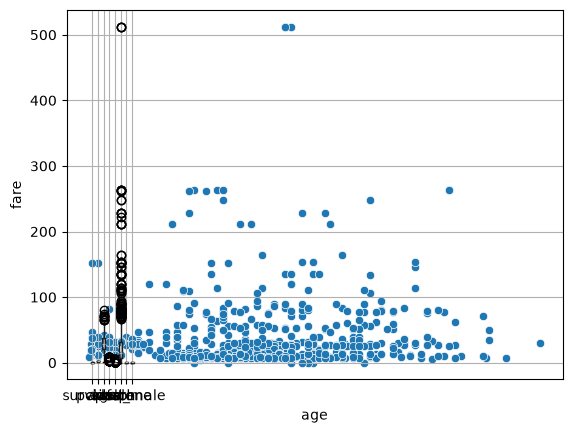

In [62]:
sns.scatterplot(df,x='age',y='fare')
plt.show()

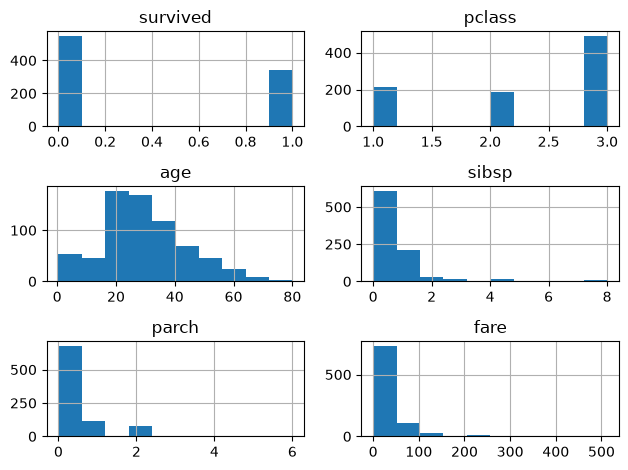

In [63]:
df.hist()
plt.tight_layout()
plt.show()

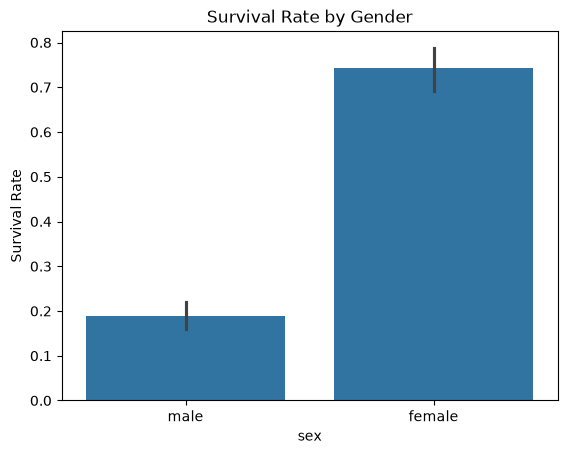

In [64]:
sns.barplot(df,x='sex', y='survived')
plt.title('Survival Rate by Gender')
plt.ylabel('Survival Rate')
plt.show()

Data Preprocessing:     
1.	Impute missing values.      
2.	Encode categorical variables using one-hot encoding or label encoding.      
3.	If needed you can apply more preprocessing methods on the given dataset.


In [65]:
miss_per=df.isnull().sum()/len(df) * 100 
miss_per.round(2)

survived        0.00
pclass          0.00
sex             0.00
age            19.87
sibsp           0.00
parch           0.00
fare            0.00
embarked        0.22
class           0.00
who             0.00
adult_male      0.00
deck           77.22
embark_town     0.22
alive           0.00
alone           0.00
dtype: float64

In [66]:
#imputing missing values
df['age']=df['age'].fillna(df['age'].median())

In [67]:
df['embarked']=df['embarked'].fillna(df['embarked'].mode()[0])

In [68]:
#dropping deck column because the missing values percentage is high
df.drop(columns=['deck'],inplace=True)

In [69]:
#droping redundant and duplicate columns provided by the seaborn dataset to prevent multicollinearity
cols_to_drop=['alive','embark_town','class','who','adult_male']
df=df.drop(columns=cols_to_drop)

In [ ]:
df.isnull().sum()

survived    0
pclass      0
sex         0
age         0
sibsp       0
parch       0
fare        0
embarked    0
alone       0
dtype: int64

In [71]:
df.duplicated().sum()

np.int64(116)

In [72]:
len(df)

891

In [73]:
df=df.drop_duplicates()

In [74]:
df.duplicated().sum(),len(df)

(np.int64(0), 775)

In [75]:
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,alone
0,0,3,male,22.0,1,0,7.2500,S,False
1,1,1,female,38.0,1,0,71.2833,C,False
2,1,3,female,26.0,0,0,7.9250,S,True
3,1,1,female,35.0,1,0,53.1000,S,False
4,0,3,male,35.0,0,0,8.0500,S,True


In [76]:
#encoding categorical columns
df['sex']=df['sex'].map({'male':0,'female':1})

In [82]:
df[1:4]

,survived,pclass,sex,age,sibsp,parch,fare,alone,embarked_Q,embarked_S
1,1,1,1,38.0,1,0,71.2833,False,False,False
2,1,3,1,26.0,0,0,7.9250,True,False,True
3,1,1,1,35.0,1,0,53.1000,False,False,True


In [78]:
#applying one-hot encoding
df=pd.get_dummies(df,columns=['embarked'],drop_first=True)

In [84]:
df[1:4]

,survived,pclass,sex,age,sibsp,parch,fare,alone,embarked_Q,embarked_S
1,1,1,1,38.0,1,0,71.2833,False,False,False
2,1,3,1,26.0,0,0,7.9250,True,False,True
3,1,1,1,35.0,1,0,53.1000,False,False,True


In [85]:
#applying standard scaler on continues values
from sklearn.preprocessing import StandardScaler

In [86]:
std_sca=StandardScaler()

In [87]:
df[['age','fare']]=std_sca.fit_transform(df[['age','fare']])

In [89]:
df[1:3]

,survived,pclass,sex,age,sibsp,parch,fare,alone,embarked_Q,embarked_S
1,1,1,1,0.611945,1,0,0.695086,False,False,False
2,1,3,1,-0.260308,0,0,-0.514627,True,False,True


Building Predictive Models:     
1.	Split the preprocessed dataset into training and testing sets.      
2.	Choose appropriate evaluation metrics (e.g., accuracy, precision, recall, F1-score) for model evaluation.       
3.	Build predictive models using LightGBM and XGBoost algorithms.      
4.	Train the models on the training set and evaluate their performance on the testing set.     
5.	Use techniques like cross-validation and hyperparameter tuning to optimize model performance.


In [93]:
from sklearn.model_selection import train_test_split,GridSearchCV

In [91]:
target=df['survived']
features=df.drop(columns=['survived'])

In [92]:
features.head()

,pclass,sex,age,sibsp,parch,fare,alone,embarked_Q,embarked_S
0,3,0,-0.551060,1,0,-0.527515,False,False,True
1,1,1,0.611945,1,0,0.695086,False,False,False
2,3,1,-0.260308,0,0,-0.514627,True,False,True
3,1,1,0.393881,1,0,0.347909,False,False,True
4,3,0,0.393881,0,0,-0.512240,True,False,True


In [94]:
x_train,x_test,y_train,y_test=train_test_split(features,target,test_size=0.2,random_state=42)

In [95]:
x_train.shape,x_test.shape,y_train.shape,y_test.shape

((620, 9), (155, 9), (620,), (155,))

In [118]:
import xgboost as xgb
import lightgbm as lgb
from sklearn.metrics import classification_report,accuracy_score

In [100]:
params={
    'n_estimators':[50,100],
    'max_depth':[3,5],
    'learning_rate':[0.1,0.01]
}

In [101]:
xgb_estimator=xgb.XGBClassifier(random_state=42,eval_metric='logloss',use_label_encoder=False)
lgb_estimator=lgb.LGBMClassifier(random_state=42)

In [102]:
xgb_grid=GridSearchCV(estimator=xgb_estimator,param_grid=params,cv=5,scoring='accuracy')
lgb_grid=GridSearchCV(estimator=lgb_estimator,param_grid=params,cv=5,scoring='accuracy')

In [105]:
xgb_grid.fit(x_train,y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","XGBClassifier...ree=None, ...)"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'learning_rate': [0.1, 0.01], 'max_depth': [3, 5], 'n_estimators': [50, 100]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls t

In [107]:
xgb_grid.best_params_

{'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 100}

In [110]:
lgb_grid.fit(x_train,y_train)

[LightGBM] [Info] Number of positive: 208, number of negative: 288
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000099 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 183
[LightGBM] [Info] Number of data points in the train set: 496, number of used features: 9
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.419355 -> initscore=-0.325422
[LightGBM] [Info] Start training from score -0.325422
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",LGBMClassifie...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'learning_rate': [0.1, 0.01], 'max_depth': [3, 5], 'n_estimators': [50, 100]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the

In [111]:
lgb_grid.best_params_

{'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 50}

In [112]:
xgb_pred=xgb_grid.predict(x_test)
lgb_pred=lgb_grid.predict(x_test)

In [113]:
print(classification_report(xgb_pred,y_test))

              precision    recall  f1-score   support

           0       0.92      0.82      0.87       106
           1       0.68      0.84      0.75        49

    accuracy                           0.83       155
   macro avg       0.80      0.83      0.81       155
weighted avg       0.84      0.83      0.83       155



In [114]:
print(classification_report(lgb_pred,y_test))

              precision    recall  f1-score   support

           0       0.91      0.80      0.85       107
           1       0.65      0.81      0.72        48

    accuracy                           0.81       155
   macro avg       0.78      0.81      0.79       155
weighted avg       0.83      0.81      0.81       155



Comparative Analysis:       
1.	Compare the performance metrics (e.g., accuracy, precision, recall) of LightGBM and XGBoost models.     
2.	Visualize and interpret the results to identify the strengths and weaknesses of each algorithm.


In [120]:
xgb_acc = accuracy_score(y_test, xgb_pred)
lgb_acc = accuracy_score(y_test, lgb_pred)

In [122]:
print(f"XGBoost Accuracy:{xgb_acc:.2f}")
print(f"LightGBM Accuracy:{lgb_acc:.2f}")

XGBoost Accuracy:0.83
LightGBM Accuracy:0.81


In [123]:
scores = pd.Series([xgb_acc, lgb_acc], index=['XGBoost', 'LightGBM'])

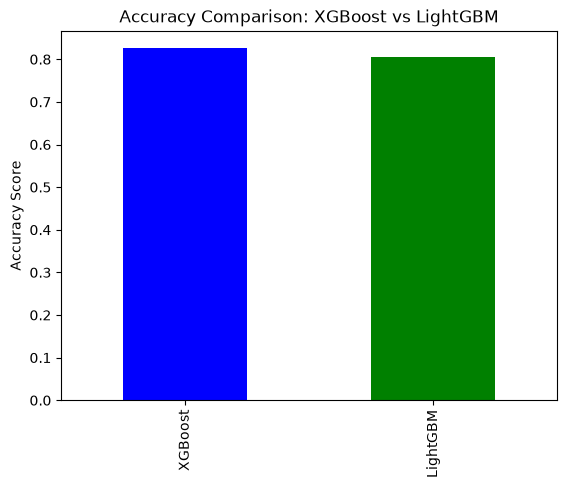

In [130]:
scores.plot(kind='bar',color=['blue','green'])
plt.title('Accuracy Comparison: XGBoost vs LightGBM')
plt.ylabel('Accuracy Score')
plt.show()